# EDA ViHSD — preprocessing UTF-8 v2

Snapshot từ pipeline đã kiểm tra; tái tạo bằng CLI `prepare`.

# EDA ViHSD — baseline PhoBERT phục vụ robustness

## Dữ liệu và phạm vi

Nguồn: archive trong GitHub chính thức `sonlam1102/vihsd`, phiên bản/checksum trong manifest.
Giữ nguyên split chính thức. Test gốc nghĩa là chưa thêm nhiễu nhân tạo; vẫn có lỗi gõ và UGC tự nhiên.
Các thống kê test chỉ mô tả dữ liệu, không dùng để lựa chọn siêu tham số hoặc sửa preprocessing.

## Phát hiện chính

- Tổng **33,400** mẫu gốc; train **24,048**, validation **2,672**, test **6,680**.
- CLEAN chiếm **82.69%** train. Accuracy cao có thể do dự đoán lớp đa số; chọn **Macro-F1** làm chỉ số chính.
- Baseline luôn đoán CLEAN trên validation: accuracy **0.8196**, Macro-F1 **0.3003**.
- Có **2** dòng rỗng sau chuẩn hóa kỹ thuật. Hai dòng rỗng thuộc train được ghi vào exclusion ledger; raw và split đánh giá giữ nguyên.
- Sau NFC/khoảng trắng: **1,177 nhóm trùng giữa các split**, **242 nhóm cùng văn bản khác nhãn** trên toàn bộ dữ liệu. Đây là giới hạn quan trọng của đánh giá split chính thức; không tự deduplicate.
- Emoji/chữ hoa/ký tự lặp là tín hiệu bề mặt, không phải nhãn độc hại. Giữ nguyên để baseline phản ánh UGC.

## Quyết định pipeline

1. Giữ nguyên train/validation/test chính thức; chỉ loại hai mẫu train không có nội dung theo ledger có ID cụ thể.
2. Unicode NFC và khoảng trắng; giữ dấu, case, emoji, URL, hashtag, teencode và ký tự kéo dài.
3. Truyền UTF-8 qua cầu nối Java để bảo toàn emoji/non-BMP, rồi RDRSegmenter và PhoBERT BPE; không xóa stopword, không sửa chính tả bằng từ điển.
4. `max_length=256` gồm special tokens. Thống kê truncation dưới đây dùng để ghi nhận mất thông tin; cấu hình được định trước và không điều chỉnh theo test.
5. Cross-entropy thường, không resampling/class weight ở lần chạy đầu. Báo cáo precision/recall/F1 theo từng lớp.

## Cách đọc số liệu

Độ dài theo khoảng trắng là số đơn vị phân cách, không phải số từ tiếng Việt sau segmentation.
Mention marker chỉ nhận `@...` hoặc placeholder, không suy ra được toàn bộ tên người được mention.
Emoji và lặp ký tự được nhận dạng heuristic nên không phải annotation chuẩn.
Không suy luận quan hệ nhân quả giữa segmentation và sai nhãn từ EDA.

## Tokenization thực tế

- **train**: median 11, p95 37, p99 64 token; cắt ở 256: 0.04%; `<unk>` trên token nội dung: 2.0900%.
- **validation**: median 11, p95 38, p99 64 token; cắt ở 256: 0.00%; `<unk>` trên token nội dung: 2.1714%.
- **test**: median 11, p95 38, p99 67 token; cắt ở 256: 0.01%; `<unk>` trên token nội dung: 2.1141%.

Không đồng nhất `<unk>` với phân mảnh: hai chỉ số được đo riêng trong bảng tokenization.



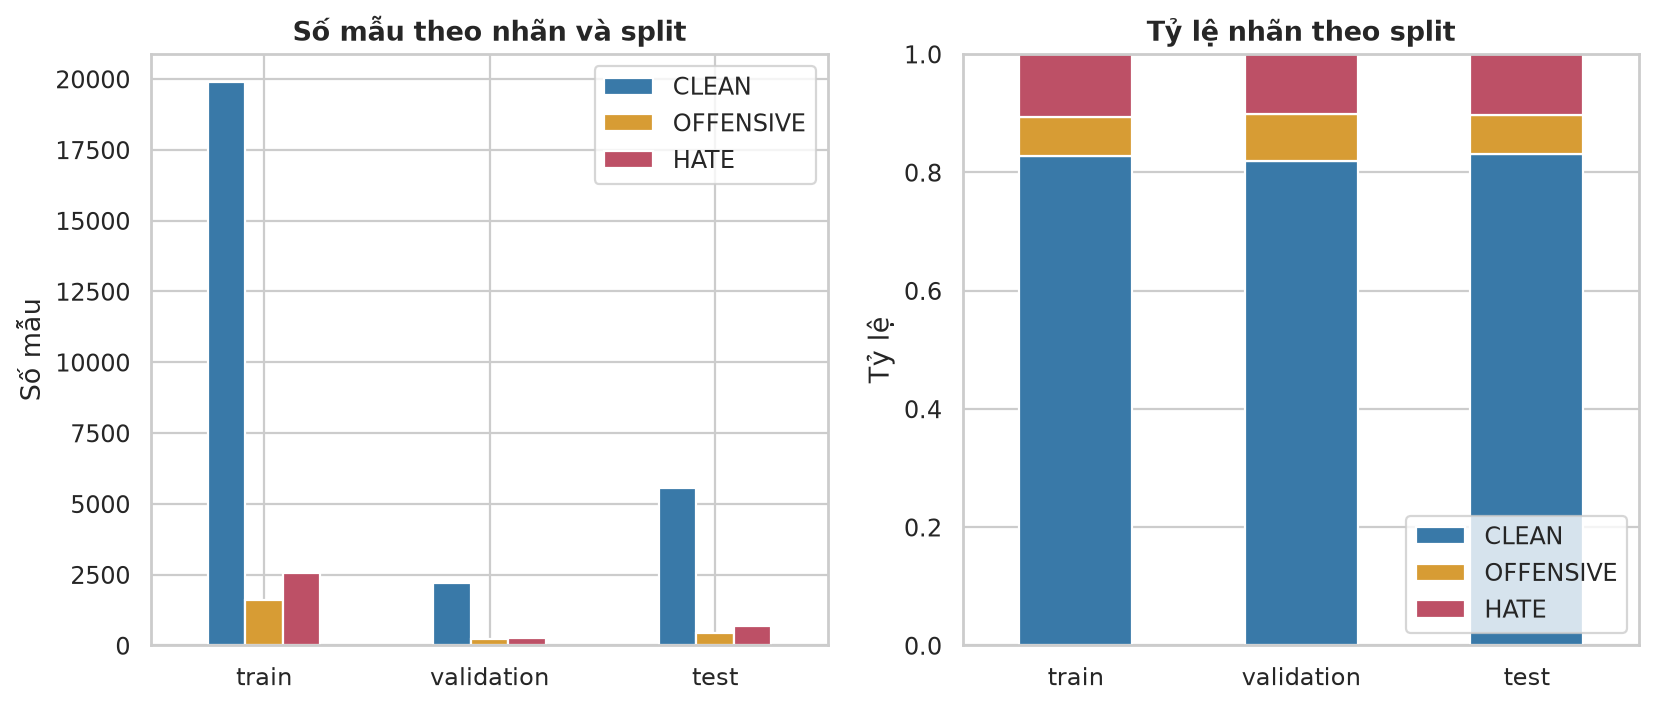

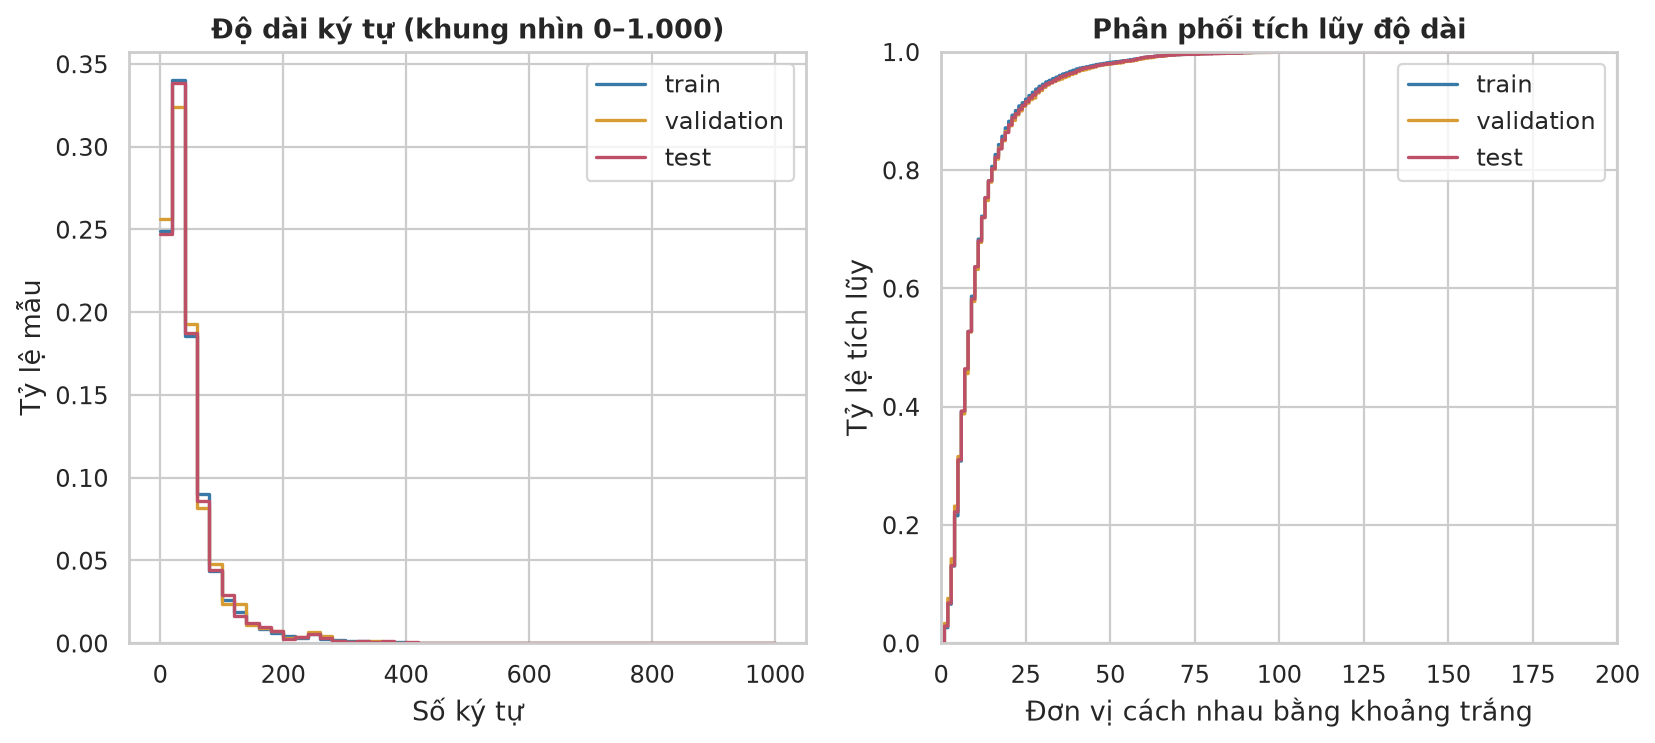

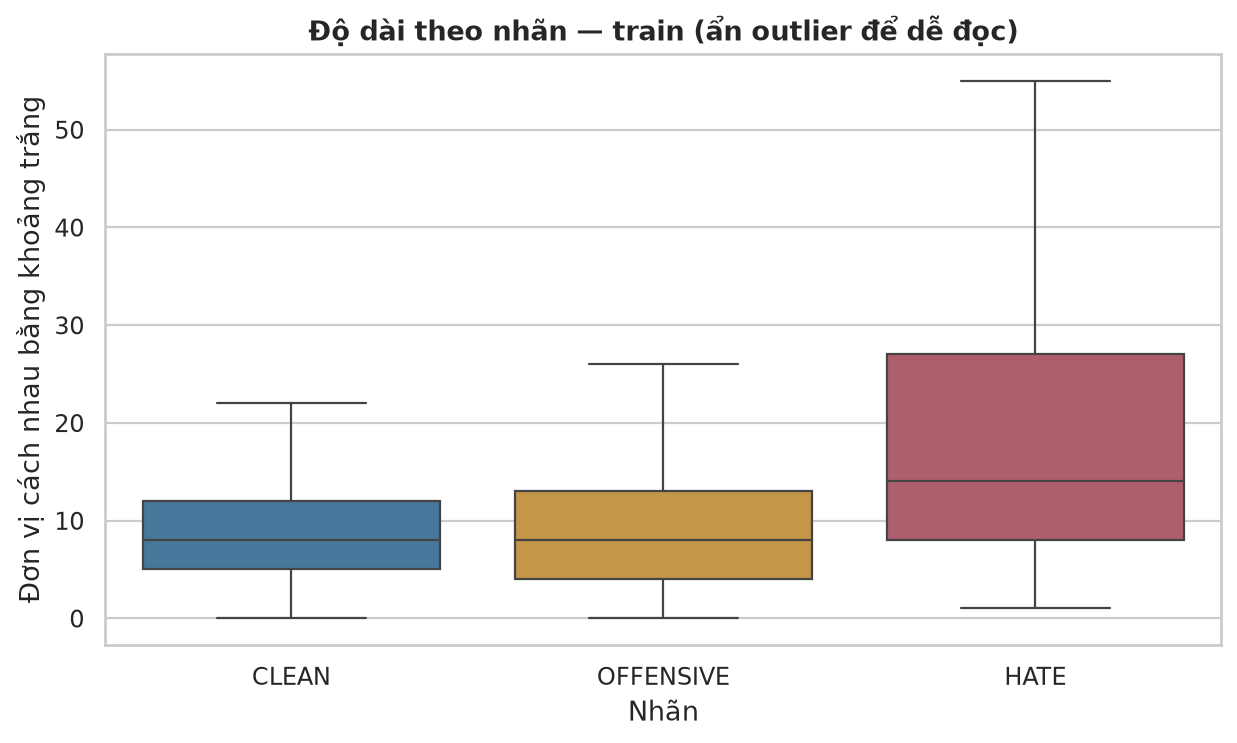

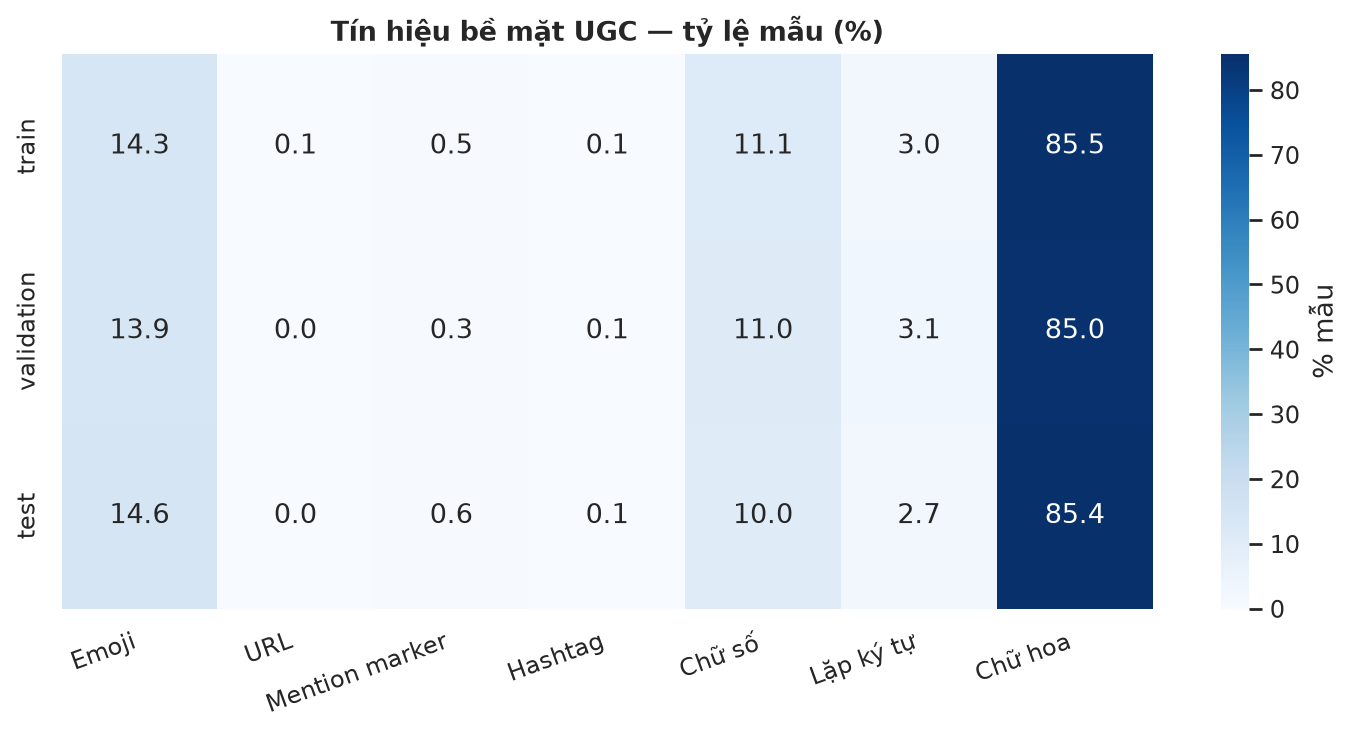

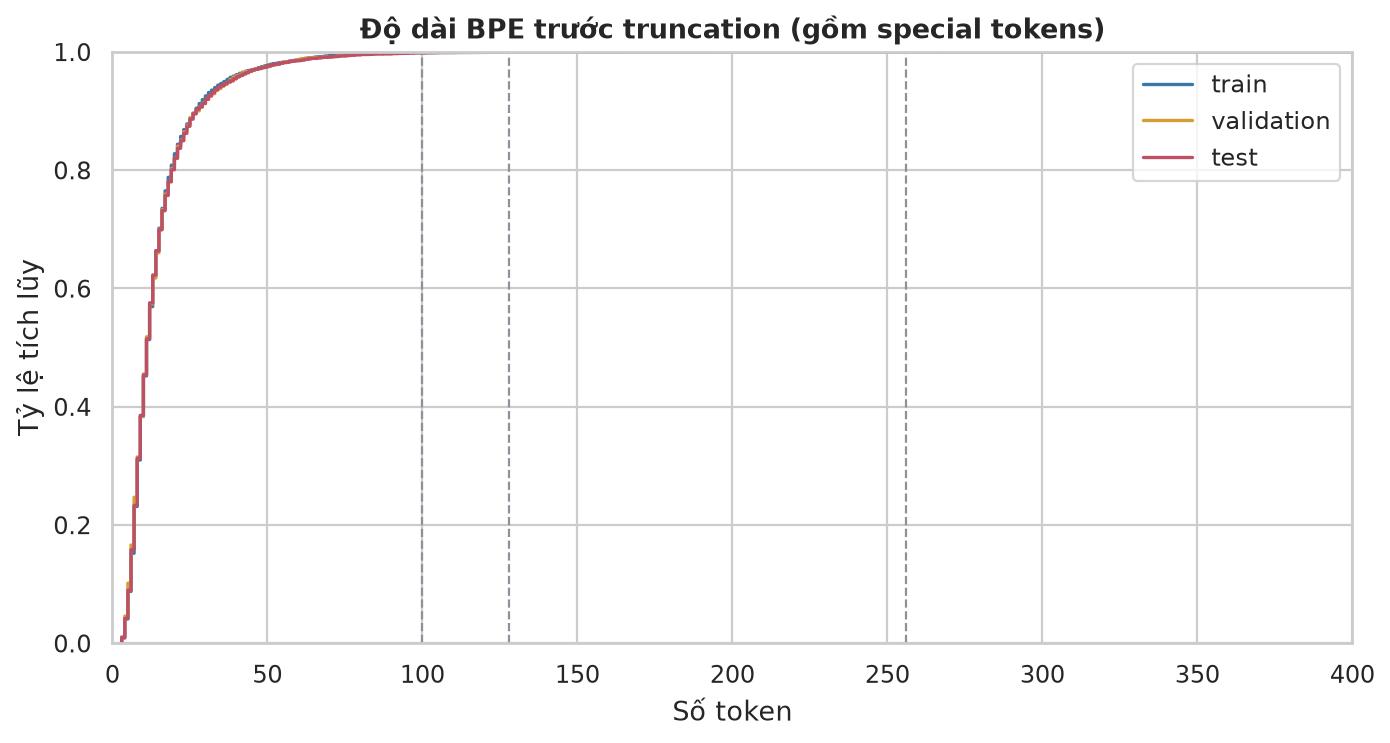

# Kiểm tra chất lượng EDA và dữ liệu trước training

## Kết quả kiểm tra

- Đã mở và kiểm tra trực quan cả 5 biểu đồ: nhãn, độ dài, độ dài theo lớp, UGC, độ dài BPE. Nhãn trục tiếng Việt đọc được, không cắt chữ.
- Số mẫu gốc khớp 33.400; train 24.048, validation 2.672, test 6.680.
- Hai văn bản rỗng chỉ thuộc train; raw giữ nguyên, tập học 24.046 mẫu.
- Train raw có outlier dài nhất 20.816 ký tự, 9.853 BPE token trước truncation. Giữ mẫu và ghi nhận cắt ở 256 token; không tự xóa vì độ dài.
- Độ dài token và `<unk>` được đo trước truncation, không nhầm với token sau cắt.
- Tokenization EDA dùng train đã loại hai dòng rỗng; EDA nhãn/bề mặt giữ đầy đủ train gốc.
- Không dùng ví dụ test để chọn preprocessing hoặc tham số.

## Trùng giữa từng cặp split

| Cặp | Nhóm văn bản chung sau NFC/khoảng trắng | Số dòng bị ảnh hưởng ở split thứ hai | Tỷ lệ |
|---|---:|---:|---:|
| train__validation | 321 | 324 | 12.13% |
| train__test | 787 | 804 | 12.04% |
| validation__test | 91 | 94 | 1.41% |

Overlap được báo theo đúng nhóm văn bản chuẩn hóa kỹ thuật, không phải near-duplicate và không tính lowercase. Giữ split chính thức ở baseline này; đây là giới hạn cần nêu khi báo cáo điểm.

## Baseline tham chiếu không cần training

- train: luôn đoán CLEAN → accuracy 0.8269; Macro-F1 0.3018.
- validation: luôn đoán CLEAN → accuracy 0.8196; Macro-F1 0.3003.
- test: luôn đoán CLEAN → accuracy 0.8305; Macro-F1 0.3025.

## Kiểm tra code

14 kiểm thử tự động đã pass, gồm dữ liệu thực, checksum, null/nhãn sai, ledger, duplicates/conflicts, tokenizer PhoBERT thật, EOS sau truncation, attention mask, model nhỏ forward/backward và Macro-F1. Notebook schema hợp lệ và tất cả code cell compile được. Kiểm tra với pretrained model thật và full training được thực hiện trên Kaggle.

## Unicode integrity

Preprocessing hợp lệ là `nfc-space-rdr-utf8-v2`. Cầu nối UTF-8 được kiểm tra trên Java thật; toàn bộ train/validation/test có 0 mẫu thay đổi chuỗi non-BMP. Version 1 không được dùng để báo cáo baseline.


# Unicode và cách diễn giải `<unk>`

## Bảo toàn Unicode

Đã sửa cầu nối Java sang `String(byte[], UTF-8)`. Kiểm tra toàn bộ train/validation/test: **0 mẫu thay đổi chuỗi ký tự non-BMP qua segmentation**. Điều này bao gồm emoji supplementary. Các kết quả của preprocessing v1 bị đánh dấu không hợp lệ và được tách riêng.

## Mẫu có `<unk>`

`<unk>` không đồng nghĩa segmentation sai; emoji cũng có thể nằm ngoài vocabulary PhoBERT.

| Split | Số mẫu | Mẫu có `<unk>` | Tỷ lệ |
|---|---:|---:|---:|
| test | 6680 | 995 | 14.90% |
| train | 24046 | 3480 | 14.47% |
| validation | 2672 | 377 | 14.11% |

## Phân tầng train theo tín hiệu emoji

| Có tín hiệu emoji | Số mẫu | Mẫu có `<unk>` | Tỷ lệ |
|---|---:|---:|---:|
| False | 20618 | 53 | 0.26% |
| True | 3428 | 3427 | 99.97% |

Đây là tương quan bề mặt, không chứng minh emoji là nguyên nhân duy nhất sinh `<unk>`. Tỷ lệ mẫu có `<unk>` khác tỷ lệ `<unk>` trên tổng token nội dung; phân mảnh BPE được đo riêng.
